In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import pickle

import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from pymo.parsers import BVHParser
from pymo.preprocessing import *
from pymo.viz_tools import *

In [2]:
p = BVHParser()

data_all = [p.parse(r'C:\Users\Aini\OneDrive\Documents\Capstone\data\InHARD_download\01-InHARD\Online\Skeleton\P01_R01.bvh')]

In [3]:
print_skel(data_all[0])

- Hips (None)
| | - Spine (Hips)
| | - Spine1 (Spine)
| | - Spine2 (Spine1)
| | - Spine3 (Spine2)
| | | | - LeftShoulder (Spine3)
| | | | - LeftArm (LeftShoulder)
| | | | - LeftForeArm (LeftArm)
| | | | - LeftHand (LeftForeArm)
| | | | | | | | - LeftInHandPinky (LeftHand)
| | | | | | | | - LeftHandPinky1 (LeftInHandPinky)
| | | | | | | | - LeftHandPinky2 (LeftHandPinky1)
| | | | | | | | - LeftHandPinky3 (LeftHandPinky2)
| | | | | | | | - LeftHandPinky3_Nub (LeftHandPinky3)
| | | | | | | - LeftInHandRing (LeftHand)
| | | | | | | - LeftHandRing1 (LeftInHandRing)
| | | | | | | - LeftHandRing2 (LeftHandRing1)
| | | | | | | - LeftHandRing3 (LeftHandRing2)
| | | | | | | - LeftHandRing3_Nub (LeftHandRing3)
| | | | | | - LeftInHandMiddle (LeftHand)
| | | | | | - LeftHandMiddle1 (LeftInHandMiddle)
| | | | | | - LeftHandMiddle2 (LeftHandMiddle1)
| | | | | | - LeftHandMiddle3 (LeftHandMiddle2)
| | | | | | - LeftHandMiddle3_Nub (LeftHandMiddle3)
| | | | | - LeftInHandIndex (LeftHand)
| | | | | - L

In [4]:
data_all[0].values.head(10)

,Hips_Xposition,Hips_Yposition,Hips_Zposition,Hips_Yrotation,Hips_Xrotation,Hips_Zrotation,RightUpLeg_Xposition,RightUpLeg_Yposition,RightUpLeg_Zposition,RightUpLeg_Yrotation,...,LeftHandPinky2_Zposition,LeftHandPinky2_Yrotation,LeftHandPinky2_Xrotation,LeftHandPinky2_Zrotation,LeftHandPinky3_Xposition,LeftHandPinky3_Yposition,LeftHandPinky3_Zposition,LeftHandPinky3_Yrotation,LeftHandPinky3_Xrotation,LeftHandPinky3_Zrotation
0 days 00:00:00,20.925001,94.647675,23.358198,-92.498489,-3.201054,-3.961121,-9.291968,-1.608512,-0.035208,-2.287457,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.008401113,21.054373,94.653931,23.394234,-92.499710,-3.200647,-3.962663,-9.287824,-1.607473,-0.034018,-2.284348,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.016802227,21.141069,94.663101,23.365467,-92.491165,-3.216289,-3.967568,-9.293797,-1.610112,-0.041713,-2.301440,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.025203340,21.217239,94.664818,23.341904,-92.514526,-3.209525,-3.982093,-9.283305,-1.613265,-0.035834,-2.343278,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.033604454,21.252237,94.668900,23.341755,-92.508110,-3.226955,-3.977323,-9.286751,-1.608990,-0.050461,-2.377383,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.042005567,21.286791,94.669937,23.351210,-92.521202,-3.250403,-3.984653,-9.289554,-1.609100,-0.048950,-2.376167,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.050406681,21.312992,94.667923,23.384684,-92.541924,-3.226573,-3.966212,-9.288270,-1.608881,-0.042163,-2.366040,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.058807794,21.362213,94.663223,23.430948,-92.585907,-3.135720,-3.934300,-9.285585,-1.610352,-0.036885,-2.336726,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.067208908,21.443485,94.660202,23.463928,-92.637596,-3.033266,-3.886676,-9.286227,-1.608671,-0.036869,-2.316190,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0
0 days 00:00:00.075610021,21.512123,94.659851,23.499193,-92.640366,-3.034676,-3.888509,-9.288905,-1.614468,-0.040075,-2.311599,...,0.0,0.0,-0.0,-24.0,1.741895,0.0,0.0,0.0,-0.0,-20.0


In [14]:
import pandas as pd

df = pd.DataFrame(data_all[0].values)
df.to_csv("output_notransf.csv", index=True)

In [5]:
dr_pipe = Pipeline([
    ('param', MocapParameterizer('expmap')),
    
])

In [5]:
dr_pipe = Pipeline([
    ('param', MocapParameterizer('position')),
    ('rcpn', RootCentricPositionNormalizer()),
    ('delta', RootTransformer('abdolute_translation_deltas')),
    ('const', ConstantsRemover()),
    ('np', Numpyfier()),
    ('down', DownSampler(2)),
    ('stdscale', ListStandardScaler())
])

In [6]:
data_all[0].values.shape

(62506, 354)

In [35]:
from pymo.preprocessing import Rotation

In [36]:
print(inspect.getsource(Rotation))

class Rotation():
    def __init__(self,rot, param_type, rotation_order, **params):
        self.rotmat = []
        self.rotation_order = rotation_order
        if param_type == 'euler':
            self._from_euler(rot[0],rot[1],rot[2], params)
        elif param_type == 'expmap':
            self._from_expmap(rot[0], rot[1], rot[2], params)

    def _from_euler(self, alpha, beta, gamma, params):
        '''Expecting degress'''

        if params['from_deg']==True:
            alpha = deg2rad(alpha)
            beta = deg2rad(beta)
            gamma = deg2rad(gamma)
        
        ca = math.cos(alpha)
        cb = math.cos(beta)
        cg = math.cos(gamma)
        sa = math.sin(alpha)
        sb = math.sin(beta)
        sg = math.sin(gamma)        

        Rx = np.asarray([[1, 0, 0], 
              [0, ca, sa], 
              [0, -sa, ca]
              ])

        Ry = np.asarray([[cb, 0, -sb], 
              [0, 1, 0],
              [sb, 0, cb]])

        Rz = np.asarray([[cg, s

In [37]:
import inspect
from pymo.preprocessing import MocapParameterizer

print(inspect.getsource(MocapParameterizer._to_expmap))

    def _to_expmap(self, X):
        '''Converts Euler angles to Exponential Maps'''

        Q = []
        for track in X:
            channels = []
            titles = []
            euler_df = track.values

            # Create a new DataFrame to store the exponential map rep
            exp_df = pd.DataFrame(index=euler_df.index)

            # Copy the root positions into the new DataFrame
            rxp = '%s_Xposition'%track.root_name
            ryp = '%s_Yposition'%track.root_name
            rzp = '%s_Zposition'%track.root_name
            exp_df[rxp] = pd.Series(data=euler_df[rxp], index=exp_df.index)
            exp_df[ryp] = pd.Series(data=euler_df[ryp], index=exp_df.index)
            exp_df[rzp] = pd.Series(data=euler_df[rzp], index=exp_df.index)
            
            # List the columns that contain rotation channels
            rots = [c for c in euler_df.columns if ('rotation' in c and 'Nub' not in c)]

            # List the joints that are not end sites, i.e., 

In [39]:
import pymo.preprocessing

print(pymo.preprocessing.__file__)

c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\preprocessing.py


In [7]:
xx = dr_pipe.fit_transform(data_all)

c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\rotation_tools.py:99: RuntimeWarning: invalid value encountered in divide
  axis = axis/(2*math.sin(theta))
c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\preprocessing.py:190: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  exp_df['%s_beta'%joint] = pd.Series(data=[e[1] for e in exps], index=exp_df.index)
c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\preprocessing.py:191: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `new

In [8]:
xx[0].values.head(10)


,Hips_Xposition,Hips_Yposition,Hips_Zposition,Hips_alpha,Hips_beta,Hips_gamma,RightUpLeg_alpha,RightUpLeg_beta,RightUpLeg_gamma,RightLeg_alpha,...,LeftInHandPinky_gamma,LeftHandPinky1_alpha,LeftHandPinky1_beta,LeftHandPinky1_gamma,LeftHandPinky2_alpha,LeftHandPinky2_beta,LeftHandPinky2_gamma,LeftHandPinky3_alpha,LeftHandPinky3_beta,LeftHandPinky3_gamma
0 days 00:00:00,20.925001,94.647675,23.358198,-0.012638,1.615170,0.098510,-0.023390,0.040788,-0.071640,-0.046680,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.008401113,21.054373,94.653931,23.394234,-0.012667,1.615191,0.098525,-0.023383,0.040733,-0.071642,-0.046678,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.016802227,21.141069,94.663101,23.365467,-0.012517,1.615048,0.098810,-0.023368,0.041034,-0.071806,-0.047092,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.025203340,21.217239,94.664818,23.341904,-0.012834,1.615455,0.098914,-0.022940,0.041748,-0.071707,-0.047380,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.033604454,21.252237,94.668900,23.341755,-0.012526,1.615348,0.099094,-0.022646,0.042334,-0.071812,-0.048137,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.042005567,21.286791,94.669937,23.351210,-0.012325,1.615585,0.099525,-0.023138,0.042335,-0.072158,-0.048302,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.050406681,21.312992,94.667923,23.384684,-0.012405,1.615936,0.098944,-0.022902,0.042147,-0.071946,-0.048480,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.058807794,21.362213,94.663223,23.430948,-0.013219,1.616670,0.097239,-0.021342,0.041573,-0.071309,-0.048853,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.067208908,21.443485,94.660202,23.463928,-0.013973,1.617533,0.095159,-0.019317,0.041133,-0.070408,-0.049412,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066
0 days 00:00:00.075610021,21.512123,94.659851,23.499193,-0.013982,1.617582,0.095204,-0.019372,0.041055,-0.070445,-0.049380,...,0,0.026898,-0.152543,0.348372,0.0,0.0,0.418879,0.0,0.0,0.349066


In [9]:
import pandas as pd

df = pd.DataFrame(xx[0].values)
df.to_csv("output4.csv", index=True)

In [16]:
print(type(xx[0]))
print(type(xx[0].values))
print(xx[0].values.index)

<class 'numpy.ndarray'>


AttributeError: 'numpy.ndarray' object has no attribute 'values'

<Axes: >

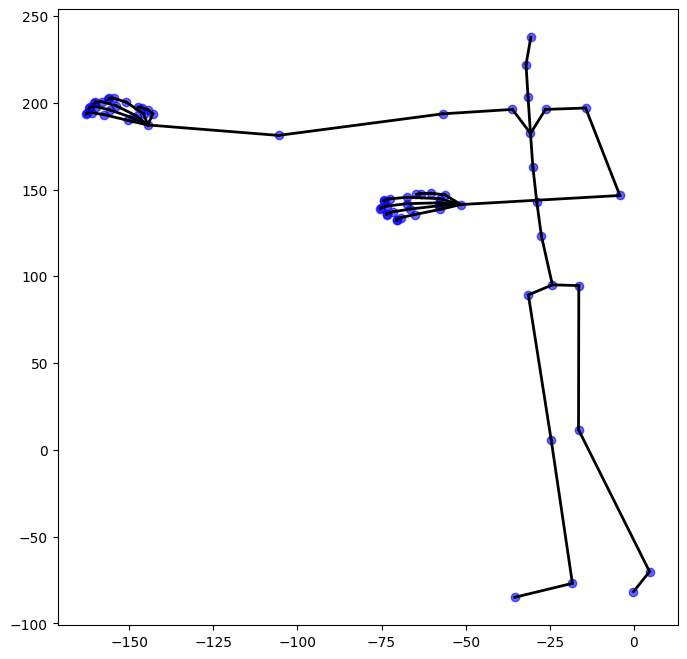

In [17]:
data_all = xx[0].values.copy()
data_all.index = range(len(data_all))

draw_stickfigure(xx[0], 600, data_all)

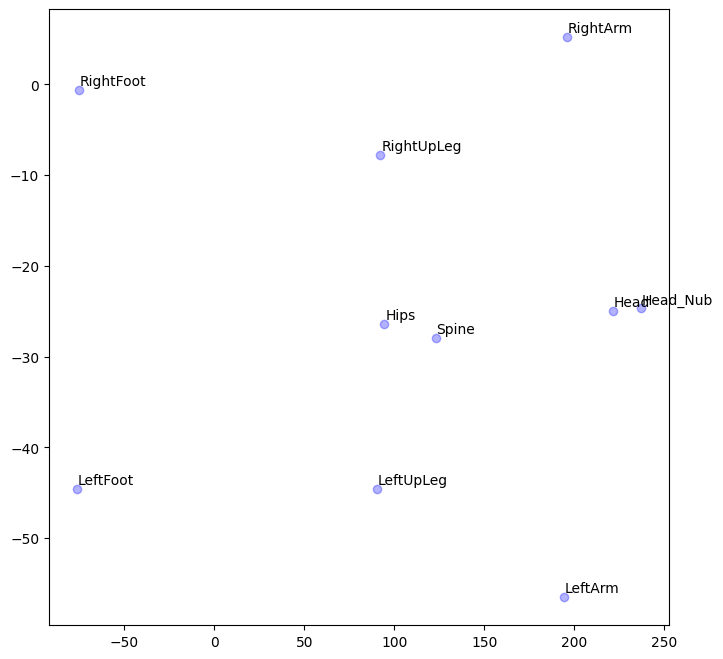

In [19]:
frame = 100
fig = plt.figure(figsize=(8,8))
#ax = fig.add_subplot(111, projection='3d')
ax = fig.add_subplot(111)
for joint in ['LeftArm', 'RightArm', 'Head', 'LeftFoot','RightFoot','Hips','Spine', 'Head_Nub','RightUpLeg', 'LeftUpLeg']:
    ax.scatter(x=data_all['%s_Yposition'%joint][frame], 
               y=-data_all['%s_Zposition'%joint][frame], 
              # zs=data_all['%s_Yposition'%joint][frame], 
               alpha=0.3, c='b', marker='o')
    ax.annotate(joint, 
                (data_all['%s_Yposition'%joint][frame] + 0.5, 
                 -data_all['%s_Zposition'%joint][frame] + 0.5))

In [26]:
import inspect
print(inspect.getsource(nb_play_mocap))

def nb_play_mocap(mocap, mf, meta=None, frame_time=1/30, scale=1, camera_z=500, base_url=None):
    data_template = 'var dataBuffer = `$$DATA$$`;'
    data_template += 'var metadata = $$META$$;'
    data_template += 'start(dataBuffer, metadata, $$CZ$$, $$SCALE$$, $$FRAMETIME$$);'
    dir_path = os.path.dirname(os.path.realpath(__file__))


    if base_url is None:
        base_url = os.path.join(dir_path, 'mocapplayer/playBuffer.html')
    
    # print(dir_path)

    if mf == 'bvh':
        pass
    elif mf == 'pos':
        cols = list(mocap.values.columns)
        for c in cols:
            if 'rotation' in c:
                cols.remove(c)
        
        data_csv = mocap.values.to_csv(index=False, columns=cols)

        if meta is not None:
            lines = [','.join(item) for item in meta.astype('str')]
            meta_csv = '[' + ','.join('[%s]'%l for l in lines) +']'            
        else:
            meta_csv = '[]'
        
        data_assigned = data_template.replace

In [27]:
nb_play_mocap(
    xx[0],
    'pos',
    scale=2,
    camera_z=800,
    frame_time=1/120
)

In [28]:
import os
import pymo

pymo_dir = os.path.dirname(pymo.__file__)
viewer_dir = os.path.join(pymo_dir, "mocapplayer")

print(viewer_dir)

c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\mocapplayer


In [29]:
import os

print(os.path.exists(
    r"c:\Users\Aini\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymo\mocapplayer\data.js"
))

True


<Axes: xlabel='Hips_Xposition', ylabel='Hips_Zposition'>

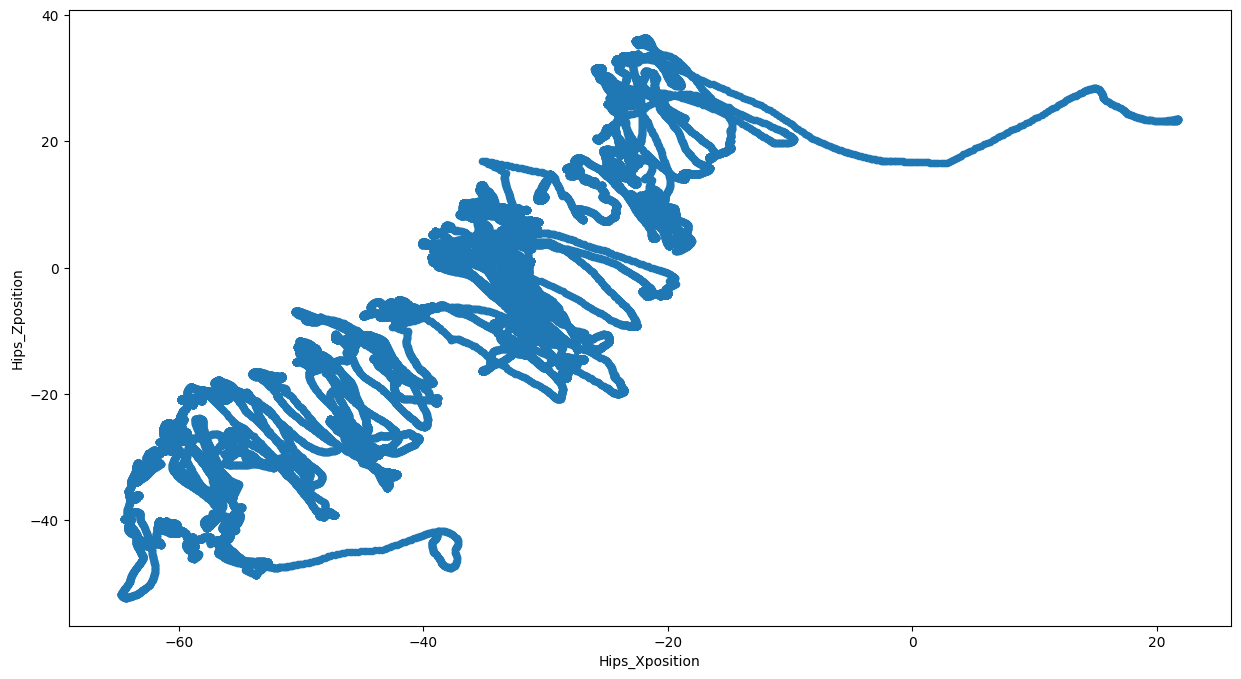

In [39]:
xx[0].values.plot.scatter(x='Hips_Xposition', y='Hips_Zposition', figsize=(15,8))

AttributeError: 'list' object has no attribute 'Hips_Xposition'

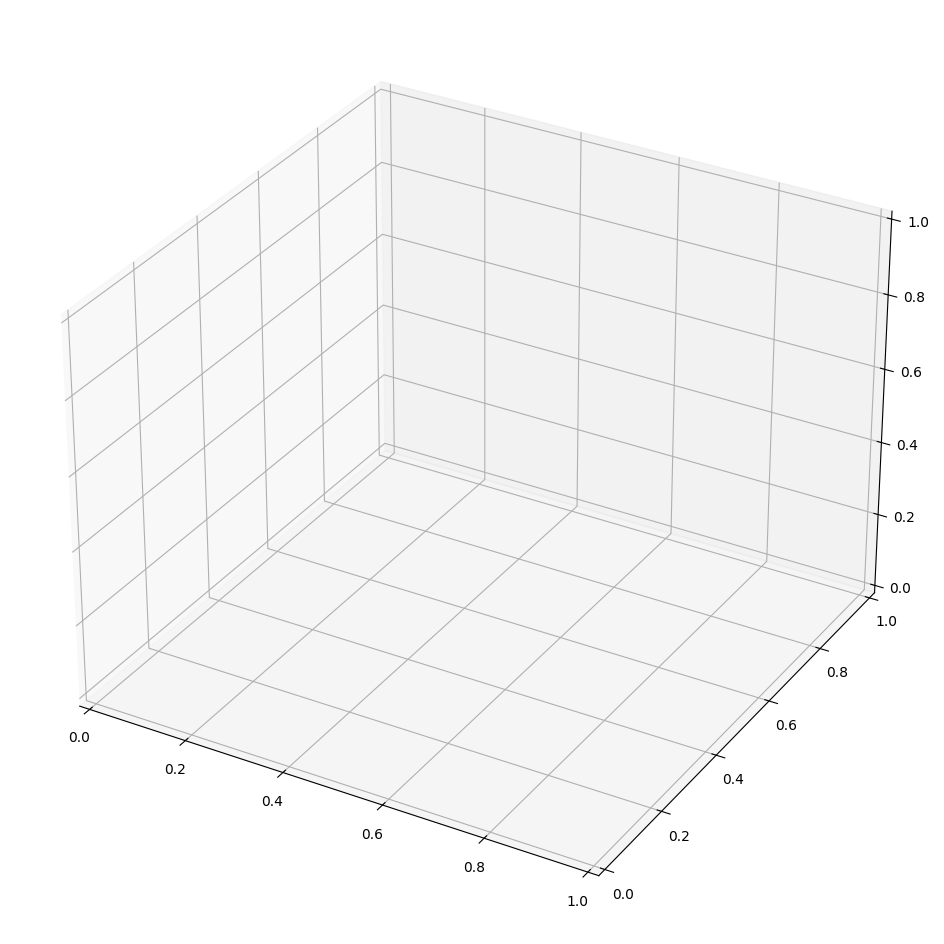

In [42]:
fig = plt.figure(figsize=(12,12))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(xx=data_all.Hips_Xposition, ys=data_all.Hips_Zposition,  zs=data_all.Hips_Yposition, alpha=0.3, c='b', marker='o')